In [3]:
import pandas as pd

df = pd.read_csv("../data/SeoulBikeData.csv", encoding="latin1")

df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [4]:
# data only for working days
model_data = df[df["Functioning Day"] == "Yes"].sort_values(["Date", "Hour"])

features = ["Hour", "Temperature(°C)", "Rainfall(mm)"]

x = model_data[features]
y = model_data["Rented Bike Count"]

print("x:", x.shape)
print("y:", y.shape)

x: (8465, 3)
y: (8465,)


In [5]:
# Split data into training (80%) and test (20%) sets
split_index = int(len(x) * 0.8)

x_train = x.iloc[:split_index] # first 80% of data
x_test = x.iloc[split_index:]  # last 20% of data

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)

Train: (6772, 3) (6772,)
Test:  (1693, 3) (1693,)


In [6]:
# DummyRegressor

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Create and train the baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(x_train, y_train)

# Predict using test data
y_pred = baseline.predict(x_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)

print(f"Baseline prediction: {y_pred[0]:.2f}")
print(f"Baseline MAE: {mae:.2f}")

Baseline prediction: 687.55
Baseline MAE: 491.51


### Baseline - DummyRegressor

We used DummyRegressor as our baseline. It always predicts the average number of rentals from the training data.  
It does not consider time, temperature, rain or any other features.

**Results:**
- Prediction: 687.55 bikes
- MAE: 491.51 bikes

This means the prediction is wrong by about 492 bikes on average. We will use this result to compare other models.

In [7]:
# Linear Regression
from sklearn.linear_model import LinearRegression

# Train the model
model = LinearRegression()
model.fit(x_train, y_train)

# Predict
linear_pred = model.predict(x_test)

# Evaluate
linear_mae = mean_absolute_error(y_test, linear_pred)

print(f"Baseline MAE: {mae:.2f}")
print(f"Linear Regression MAE: {linear_mae:.2f}")

Baseline MAE: 491.51
Linear Regression MAE: 363.41


Linear Regression works better, but the error is still pretty high. I think it's because the relationship between the features and bike rentals isn't linear.

In [8]:
# Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Train the model
tree = DecisionTreeRegressor(max_depth=5, random_state=42) # TODO try different values
tree.fit(x_train, y_train)

# Predict
tree_pred = tree.predict(x_test)

# Evaluate
tree_mae = mean_absolute_error(y_test, tree_pred)

print(f"Baseline MAE: {mae:.2f}")
print(f"Linear Regression MAE: {linear_mae:.2f}")
print(f"Decision Tree MAE: {tree_mae:.2f}")

Baseline MAE: 491.51
Linear Regression MAE: 363.41
Decision Tree MAE: 309.42


Decision Tree gives a better result, but the error is still pretty high — almost 50% of the average number of rentals.  
We noticed a difference between weekdays and weekends during EDA, so let's try adding this as another feature.

In [9]:
# Add IsWeekend
model_data["IsWeekend"] = (model_data["Date"].dt.day_of_week  >= 5).astype(int)

x_weekend = model_data[features + ["IsWeekend"]]

x_train_weekend = x_weekend.iloc[:split_index]
x_test_weekend = x_weekend.iloc[split_index:]

tree_weekend = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_weekend.fit(x_train_weekend, y_train)

weekend_pred = tree_weekend.predict(x_test_weekend)
weekend_mae = mean_absolute_error(y_test, weekend_pred)

print(f"Original Decision Tree MAE: {tree_mae:.2f}")
print(f"With IsWeekend MAE: {weekend_mae:.2f}")

Original Decision Tree MAE: 309.42
With IsWeekend MAE: 309.93


Adding **IsWeekend** didn't help. The error even increased a little. Maybe the tree is too simple to make good use of this feature.

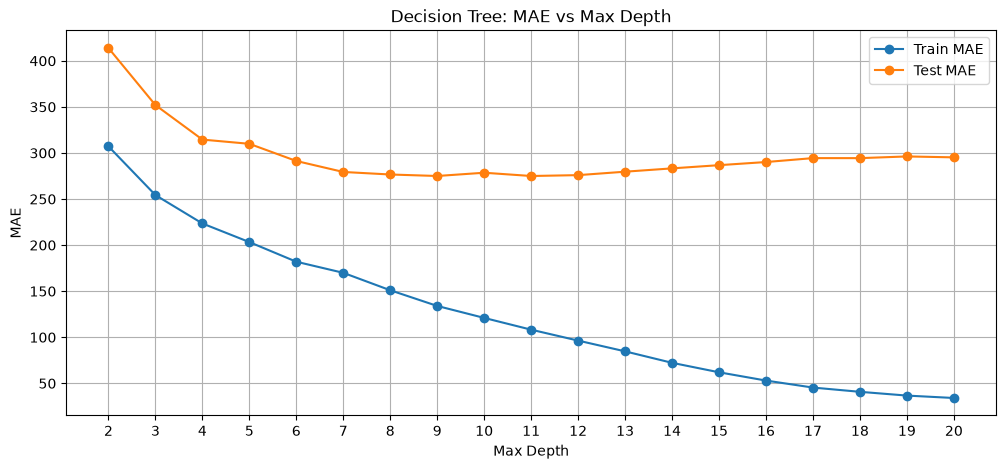

In [10]:
# Trying different max_depth
import matplotlib.pyplot as plt

train_errors = []
test_errors = []
depths = range(2, 21)

for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(x_train_weekend, y_train)

    train_pred = tree.predict(x_train_weekend)
    test_pred = tree.predict(x_test_weekend)

    train_errors.append(mean_absolute_error(y_train, train_pred))
    test_errors.append(mean_absolute_error(y_test, test_pred))

plt.figure(figsize=(12, 5))
plt.plot(depths, train_errors, marker="o", label="Train MAE")
plt.plot(depths, test_errors, marker="o", label="Test MAE")

plt.title("Decision Tree: MAE vs Max Depth")
plt.xlabel("Max Depth")
plt.ylabel("MAE")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

Tested different **max_depth**. The best results were around **9–12**. After that, the training error kept decreasing, but the test error started increasing. This looks like overfitting.

=============================================================================================================
## Train / Validation / Test

Until now Test data was used to find the best `max_depth` which is not a good idea.  
So the data is now split into three parts: Train (70%), Validation (15%) and Test (15%).  
Validation is used to find the best parameters, while Test is kept for the final check.

In [11]:
# Train (70%) / Validation (15%) / Test (15%) split
train_end = int(len(x_weekend) * 0.70)
val_end = int(len(x_weekend) * 0.85)

x_train_v = x_weekend.iloc[:train_end]
x_val = x_weekend.iloc[train_end:val_end]
x_test_v = x_weekend.iloc[val_end:]

y_train_v = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test_v = y.iloc[val_end:]

print("Train:", x_train_v.shape, y_train_v.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test_v.shape, y_test_v.shape)

Train: (5925, 4) (5925,)
Validation: (1270, 4) (1270,)
Test: (1270, 4) (1270,)


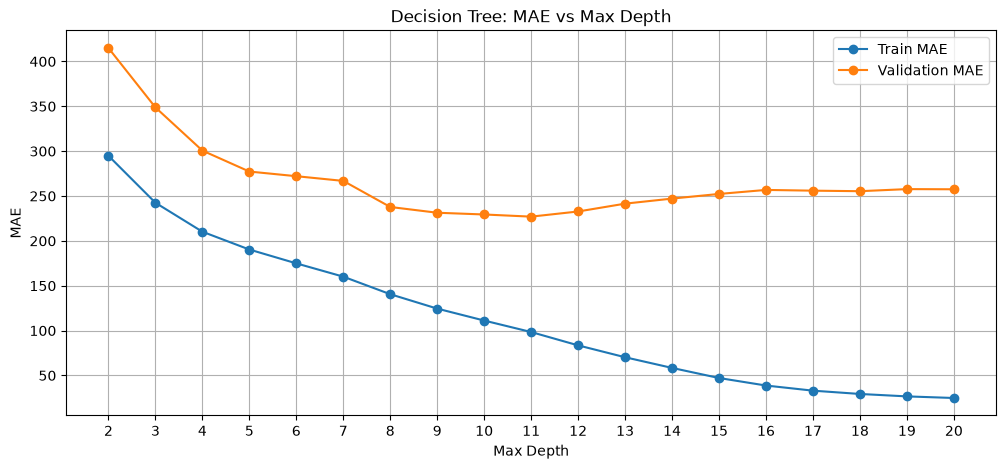

In [18]:
train_errors = []
val_errors = []
depths = range(2, 21)

for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(x_train_v, y_train_v)

    train_pred = tree.predict(x_train_v)
    val_pred = tree.predict(x_val)

    train_errors.append(mean_absolute_error(y_train_v, train_pred))
    val_errors.append(mean_absolute_error(y_val, val_pred))

plt.figure(figsize=(12, 5))
plt.plot(depths, train_errors, marker="o", label="Train MAE")
plt.plot(depths, val_errors, marker="o", label="Validation MAE")

plt.title("Decision Tree: MAE vs Max Depth")
plt.xlabel("Max Depth")
plt.ylabel("MAE")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

Overfitting is clearer on this graph. The training error keeps going down, but the validation error starts going up after about depth 11.  
This suggests that the model becomes too complex.

In [15]:
# Find the best max_depth using validation results
best_depth = depths[val_errors.index(min(val_errors))]

# Train the final model on Train + Validation
final_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=42
)

final_tree.fit(
    x_weekend.iloc[:val_end],
    y.iloc[:val_end]
)

# Evaluate on Test
final_pred = final_tree.predict(x_test_v)
final_mae = mean_absolute_error(y_test_v, final_pred)

print(f"Best max_depth: {best_depth}")
print(f"Validation MAE: {min(val_errors):.2f}")
print(f"Final Test MAE: {final_mae:.2f}")

Best max_depth: 11
Validation MAE: 227.00
Final Test MAE: 289.88


In [16]:
# Combine Train and Validation for final training
x_train_final = x_weekend.iloc[:val_end]
y_train_final = y.iloc[:val_end]

# Baseline
baseline_final = DummyRegressor(strategy="mean")
baseline_final.fit(x_train_final, y_train_final)

baseline_final_mae = mean_absolute_error(
    y_test_v,
    baseline_final.predict(x_test_v)
)

# Linear Regression
linear_final = LinearRegression()
linear_final.fit(x_train_final, y_train_final)

linear_final_mae = mean_absolute_error(
    y_test_v,
    linear_final.predict(x_test_v)
)

# Compare all models
print(f"Baseline MAE:          {baseline_final_mae:.2f}")
print(f"Linear Regression MAE: {linear_final_mae:.2f}")
print(f"Decision Tree MAE:     {final_mae:.2f}")

Baseline MAE:          444.34
Linear Regression MAE: 339.33
Decision Tree MAE:     289.88


**Decision Tree** gives the best result so far. The error is still quite high, but much lower than with **DummyRegressor** or **Linear Regression**.